In [1]:
import numpy as np 
import pandas as pd

df = pd.read_csv(r"D:\Coding\kaggle\RSNA\data\main_data\train (1).csv")

In [2]:
cols = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

filtered_df = df[df[cols].notna().all(axis=1)]
filtered_df.to_csv(r"D:\Coding\kaggle\RSNA\data\main_data\available_labels.csv", index=False)


In [3]:
df = pd.read_csv(r"D:\Coding\kaggle\RSNA\data\main_data\available_labels.csv")
df[cols] = np.nan
df.to_csv(r"D:\Coding\kaggle\RSNA\data\main_data\without_labels.csv")


===== RESULTS =====

          Column  N  Accuracy      AUC  Precision   Recall       F1
             ACL 58  0.844828 0.867647   0.727273 1.000000 0.842105
             MCL 58  0.879310 0.928571   0.562500 1.000000 0.720000
 Medial Meniscus 58  0.844828 0.848558   0.793103 0.884615 0.836364
Lateral Meniscus 58  0.844828 0.841615   0.791667 0.826087 0.808511
       Medial OA 58  0.862069 0.885271   0.666667 0.933333 0.777778
      Lateral OA 58  0.810345 0.813346   0.500000 0.818182 0.620690
           PF OA 58  0.793103 0.796654   0.680000 0.809524 0.739130
        Effusion 58  0.724138 0.652174   0.686275 1.000000 0.813953
       Synovitis 58  0.689655 0.676225   0.764706 0.481481 0.590909
         Baker's 58  0.896552 0.903986   0.687500 0.916667 0.785714
       Contusion 58  0.810345 0.818489   0.666667 0.842105 0.744186
        Fracture 58  0.793103 0.788889   0.636364 0.777778 0.700000


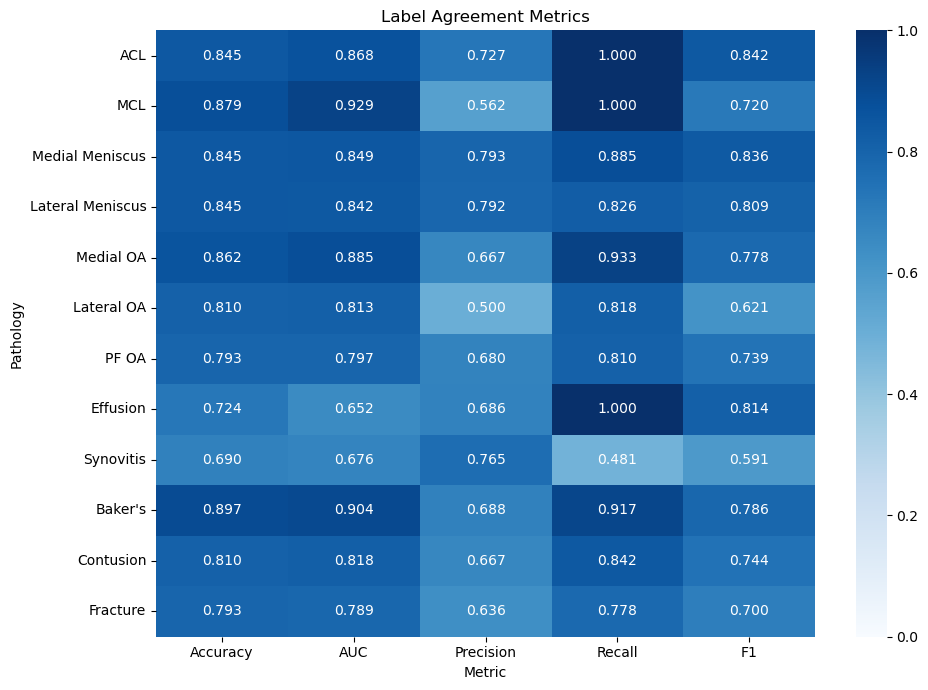

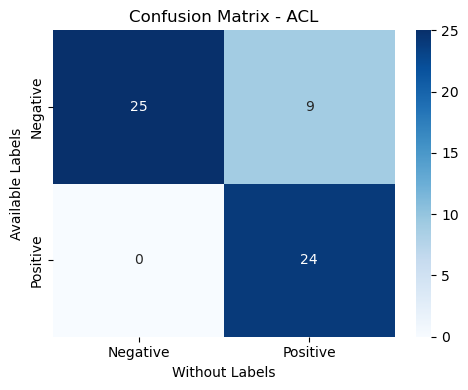

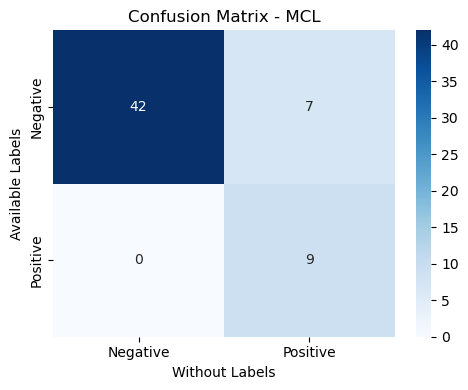

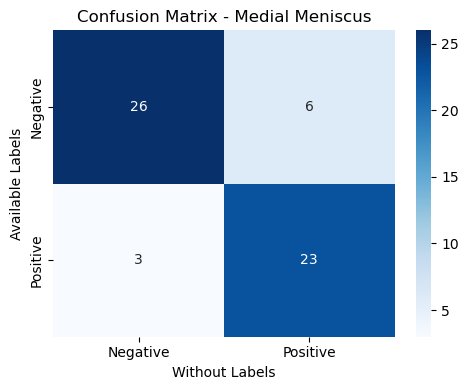

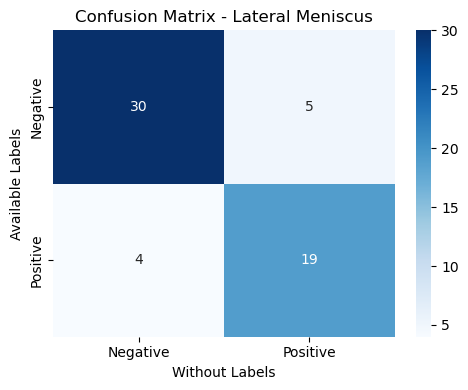

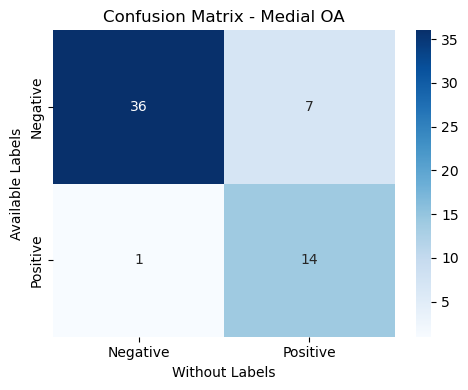

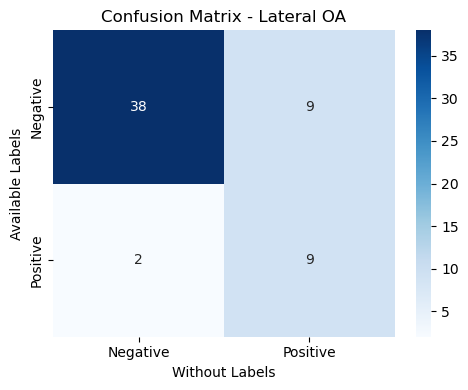

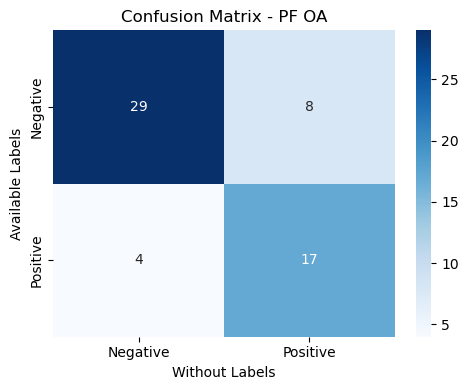

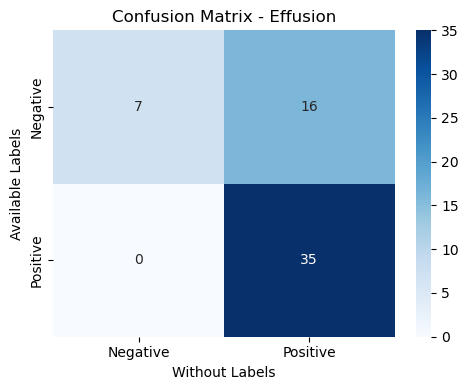

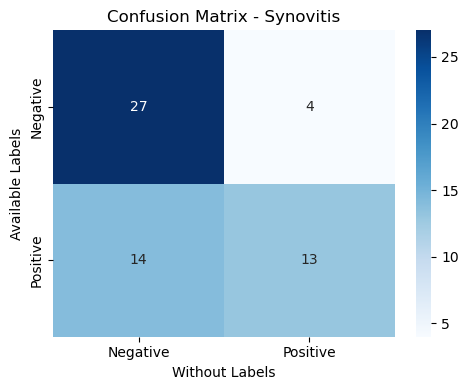

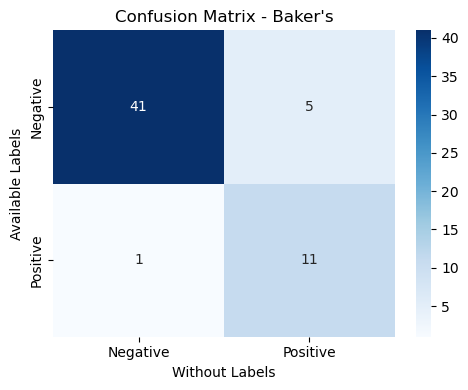

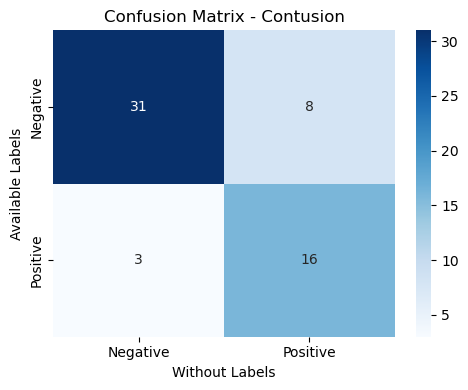

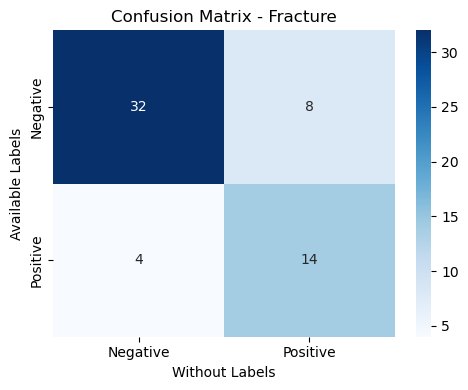

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# ============================================================
# FILES
# ============================================================

pred_file = r"D:\Coding\kaggle\RSNA\data\main_data\without_labels.csv"
true_file = r"D:\Coding\kaggle\RSNA\data\main_data\available_labels.csv"

pred_df = pd.read_csv(pred_file)
true_df = pd.read_csv(true_file)


# ============================================================
# COLUMNS
# ============================================================

cols = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]


# ============================================================
# RESULTS
# ============================================================

results = []
confusion_matrices = {}

for col in cols:

    # Only compare rows where BOTH sources have a label
    mask = pred_df[col].notna() & true_df[col].notna()

    y_true = true_df.loc[mask, col]
    y_pred = pred_df.loc[mask, col]

    # Metrics
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # AUC
    try:
        auc = roc_auc_score(y_true, y_pred)
    except ValueError:
        auc = np.nan

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    confusion_matrices[col] = cm

    results.append({
        "Column": col,
        "N": len(y_true),
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })


# ============================================================
# RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(results)

print("\n===== RESULTS =====\n")
print(results_df.to_string(index=False))


# ============================================================
# SAVE RESULTS
# ============================================================

results_df.to_csv(
    r"D:\Coding\kaggle\RSNA\data\main_data\label_comparison.csv",
    index=False
)


# ============================================================
# METRIC HEATMAP
# ============================================================

metric_df = results_df.set_index("Column")[
    ["Accuracy", "AUC", "Precision", "Recall", "F1"]
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    metric_df,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Label Agreement Metrics")
plt.xlabel("Metric")
plt.ylabel("Pathology")

plt.tight_layout()
plt.show()


# ============================================================
# CONFUSION MATRIX HEATMAPS
# ============================================================

for col in cols:

    cm = confusion_matrices[col]

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    plt.title(f"Confusion Matrix - {col}")

    plt.xlabel("Without Labels")
    plt.ylabel("Available Labels")

    plt.tight_layout()
    plt.show()

In [ ]:
import pydicom

ds = pydicom.dcmread(r"D:\Coding\kaggle\RSNA\data\Raw_dicom\test_series\1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402\1.2.826.0.1.3680043.8.498.10927312244766790279817592893017048392\1.2.826.0.1.3680043.8.498.10707293358718170665656804341202443292.dcm")

print(ds)